1- Klasorleri okuyup etiketleyerek numpy array haline getirilecek

2- Datayı normalize edip istenilen float32 formatına ayarlanacak

3- Generator ve discriminator fonksiyonları yazılacak 

4- GANs modeli yazılıp çalıştırılacak

5- Modeli kaydetip numarasına göre kontrol edilecek




In [ ]:
from glob import glob 
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
from keras_preprocessing.image import image_data_generator,img_to_array,load_img
from numpy import asarray
from keras.models import Model,Sequential,load_model
from keras.layers import Dense,Dropout,Input,ReLU
from tensorflow.keras.optimizers import Adam
from tqdm import tqdm
import cv2
from PIL import Image

In [ ]:
train_path  = '/content/drive/MyDrive/MURA ELBOW SON/TRAİN/XR_ELBOW'
 

In [ ]:
"""image_names = []
def getImagePaths2(path):

    for dirname, _, filenames in os.walk(path):
        for filename in filenames:
            fullpath = os.path.join(dirname, filename)
            image_names.append(fullpath)
    return image_names"""

'image_names = []\ndef getImagePaths2(path):\n\n    for dirname, _, filenames in os.walk(path):\n        for filename in filenames:\n            fullpath = os.path.join(dirname, filename)\n            image_names.append(fullpath)\n    return image_names'

In [ ]:
"""veri = []
boyut = 64
kanal = 3
def getImagePaths(path):

    for dirname, _, filenames in os.walk(path):
        for filename in filenames:
          fullpath = os.path.join(dirname, filename)
          resim = cv2.imread(fullpath, cv2.IMREAD_COLOR)
          if(resim is not None):
            resim = cv2.resize(resim,(boyut,boyut))
            veri.append([resim])
          
           
    return veri"""

'veri = []\nboyut = 64\nkanal = 3\ndef getImagePaths(path):\n\n    for dirname, _, filenames in os.walk(path):\n        for filename in filenames:\n          fullpath = os.path.join(dirname, filename)\n          resim = cv2.imread(fullpath, cv2.IMREAD_COLOR)\n          if(resim is not None):\n            resim = cv2.resize(resim,(boyut,boyut))\n            veri.append([resim])\n          \n           \n    return veri'

In [ ]:
veri = []
boyut = 64
for dirname, _, filenames in os.walk(train_path):
  for filename in filenames:
    fullpath = os.path.join(dirname, filename)
    resim = cv2.imread(fullpath, cv2.IMREAD_GRAYSCALE)
    if(resim is not None):
      resim = cv2.resize(resim,(28,28))
      #resim = cv2.cvtColor(resim, cv2.COLOR_BGR2RGB)
      veri.append([resim])
          

In [ ]:
for i in veri:
  print(np.shape(i))

In [ ]:
np.shape(veri)

(860, 1, 28, 28)

In [ ]:
veri = np.array(veri).reshape(-1,28,28).astype('float32')

In [ ]:
veri.shape

(860, 28, 28)

In [ ]:
for img in veri:
  print(img.shape)

In [ ]:
 veri = (veri.astype(np.float32)-127.5)/127.5

In [ ]:
veri = veri.reshape(veri.shape[0],veri.shape[1]*veri.shape[2])

In [ ]:
veri.shape

(860, 784)

In [ ]:
"""veri = []
for dirname, _, filenames in os.walk(train_path):
  for filename in filenames:
    fullpath = os.path.join(dirname, filename)
    resim= Image.open(fullpath)
    resim = img_to_array(resim)
    veri.append(resim)"""

'veri = []\nfor dirname, _, filenames in os.walk(train_path):\n  for filename in filenames:\n    fullpath = os.path.join(dirname, filename)\n    resim= Image.open(fullpath)\n    resim = img_to_array(resim)\n    veri.append(resim)'

In [ ]:
def create_generator():
  generator = Sequential()
  
  generator.add(Dense(units = 512, input_dim = 100))
  generator.add(ReLU())


  generator.add(Dense(units = 1024))
  generator.add(ReLU())

  generator.add(Dense(units = 784,activation = "tanh"))


  generator.compile(loss = "binary_crossentropy", optimizer = Adam(lr = 0.0001,beta_1 = 0.5))

  return generator

In [ ]:
g = create_generator()
g.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_14 (Dense)            (None, 512)               51712     
                                                                 
 re_lu_12 (ReLU)             (None, 512)               0         
                                                                 
 dense_15 (Dense)            (None, 1024)              525312    
                                                                 
 re_lu_13 (ReLU)             (None, 1024)              0         
                                                                 
 dense_16 (Dense)            (None, 784)               803600    
                                                                 
Total params: 1,380,624
Trainable params: 1,380,624
Non-trainable params: 0
_________________________________________________________________


In [ ]:
def create_discriminator():
  discriminator = Sequential()
  
  discriminator.add(Dense(units = 1024, input_dim = 784 ))
  discriminator.add(ReLU())
  discriminator.add(Dropout(0.4))


  
  discriminator.add(Dense(units = 512))
  discriminator.add(ReLU())
  discriminator.add(Dropout(0.4))
  
  
  discriminator.add(Dense(units = 256))
  discriminator.add(ReLU())

  discriminator.add(Dense(units = 1,activation="sigmoid"))

  discriminator.compile(loss = "binary_crossentropy", optimizer = Adam(lr = 0.0001,beta_1 = 0.5) )

  return discriminator



In [ ]:
d =  create_discriminator()
d.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_17 (Dense)            (None, 1024)              803840    
                                                                 
 re_lu_14 (ReLU)             (None, 1024)              0         
                                                                 
 dropout_6 (Dropout)         (None, 1024)              0         
                                                                 
 dense_18 (Dense)            (None, 512)               524800    
                                                                 
 re_lu_15 (ReLU)             (None, 512)               0         
                                                                 
 dropout_7 (Dropout)         (None, 512)               0         
                                                                 
 dense_19 (Dense)            (None, 256)              

In [ ]:
def create_gan(discriminator,generator):
  discriminator.trainable = False
  gan_input = Input(shape = (100, ) )

  x = generator(gan_input)
  gan_output = discriminator(x)

  gan = Model(inputs = gan_input, outputs = gan_output)

  gan.compile(loss = "binary_crossentropy", optimizer = "adam")
  return gan



In [ ]:
gan = create_gan(d,g)
gan.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 100)]             0         
                                                                 
 sequential_2 (Sequential)   (None, 784)               1380624   
                                                                 
 sequential_3 (Sequential)   (None, 1)                 1460225   
                                                                 
Total params: 2,840,849
Trainable params: 1,380,624
Non-trainable params: 1,460,225
_________________________________________________________________


In [ ]:
veri.shape[0]

860

In [ ]:
epochs = 50
batch_size = 256

noise = np.random.normal(0,1, [batch_size,100])

generated_images = g.predict(noise)

image_batch = veri[np.random.randint(low= 0, high = veri.shape[0],size = batch_size)]

print(generated_images.shape)
print(image_batch.shape)

(256, 784)
(256, 784)


In [ ]:

epochs = 50
batch_size = 256


for e in range(epochs):
  for _ in range(batch_size):
    noise = np.random.normal(0,1, [batch_size,100])

    generated_images = g.predict(noise)

    image_batch = veri[np.random.randint(low= 0, high = veri.shape[0],size = batch_size)]

    x = np.concatenate([image_batch, generated_images])

    y_dis = np.zeros(batch_size*2)
    y_dis[:batch_size] = 1

    d.trainable = True
    d.train_on_batch(x,y_dis)

    noise = np.random.normal(0,1,[batch_size,100])

    y_gen = np.ones(batch_size)

    d.trainable = False
    gan.train_on_batch(noise,y_gen)
  print("epochs: ",e)

epochs:  0
epochs:  1
epochs:  2
epochs:  3
epochs:  4
epochs:  5
epochs:  6
epochs:  7
epochs:  8
epochs:  9
epochs:  10
epochs:  11
epochs:  12
epochs:  13
epochs:  14
epochs:  15
epochs:  16
epochs:  17
epochs:  18
epochs:  19
epochs:  20
epochs:  21
epochs:  22
epochs:  23
epochs:  24
epochs:  25
epochs:  26
epochs:  27
epochs:  28
epochs:  29
epochs:  30
epochs:  31
epochs:  32
epochs:  33
epochs:  34
epochs:  35
epochs:  36
epochs:  37
epochs:  38
epochs:  39
epochs:  40
epochs:  41
epochs:  42
epochs:  43
epochs:  44
epochs:  45
epochs:  46
epochs:  47
epochs:  48
epochs:  49


In [ ]:
import keras
import tensorflow as tf
from keras.models import load_model
g.save("gans_model.h5")

g_load = load_model("/content/gans_model.h5")

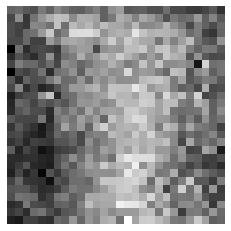

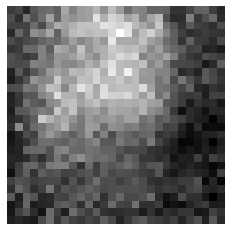

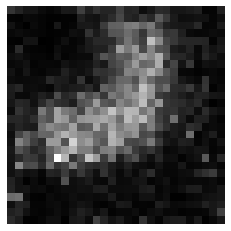

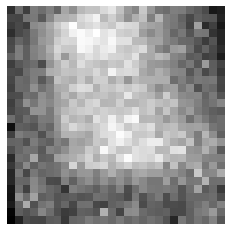

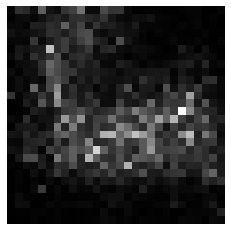

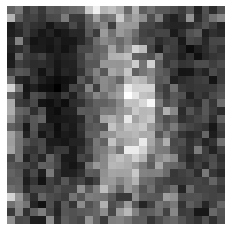

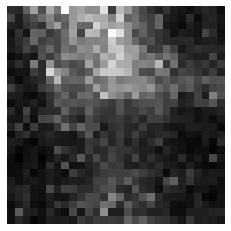

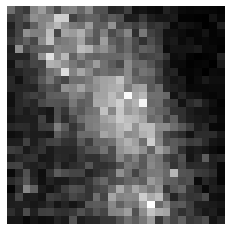

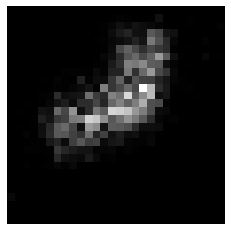

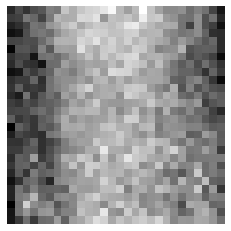

In [ ]:
noise = np.random.normal(loc= 0, scale = 1,size=[100,100])
generated_images =  g_load.predict(noise)
generated_images = generated_images.reshape(100,28,28)

for i in range(0,10,1):
  plt.imshow(generated_images[i],cmap = "gray", interpolation = "nearest")
  plt.axis("off"),plt.show()

